In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("/content/Mall_Customers.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
df.shape

(200, 5)

In [7]:
df.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [8]:
df["Genre"] = df["Genre"].map({"Male":0, "Female":1})

In [9]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


Grouping customers based on their age, earning, and spending behavior!!

In [10]:
X = X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

In [11]:
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


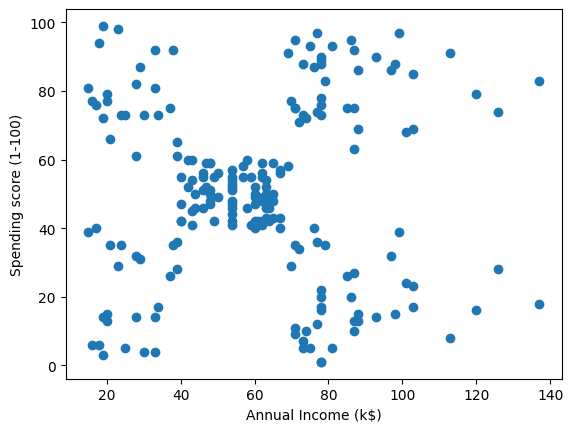

In [12]:
plt.scatter(df['Annual Income (k$)'],df['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending score (1-100)')
plt.show()

In [13]:
model = KMeans(n_clusters=2, random_state=42)
model.fit(X)

KMeans(n_clusters=2, random_state=42)

In [14]:
df['cluster'] = model.labels_

In [15]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,0,19,15,39,0
1,2,0,21,15,81,0
2,3,1,20,16,6,0
3,4,1,23,16,77,0
4,5,1,31,17,40,0


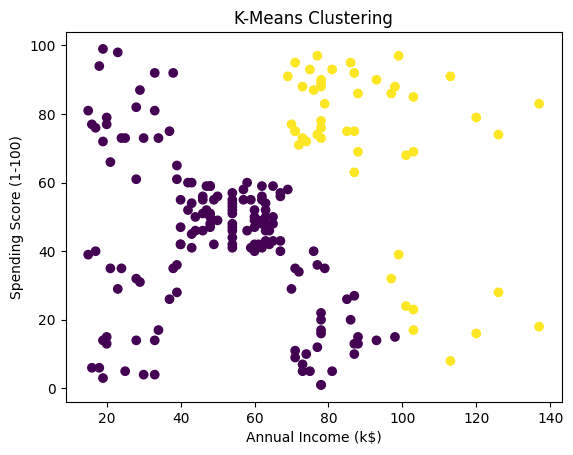

In [16]:
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["cluster"]
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering")

plt.show()

In [17]:
model.cluster_centers_

array([[40.33552632, 50.90789474, 43.63157895],
       [34.14583333, 91.125     , 71.        ]])

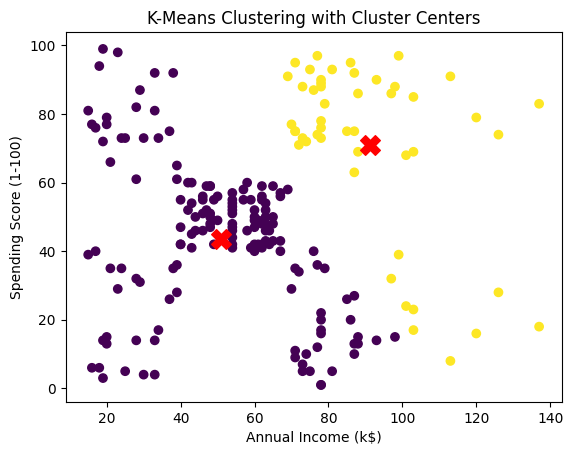

In [18]:
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["cluster"]
)

plt.scatter(
    model.cluster_centers_[:, 1],
    model.cluster_centers_[:, 2],
    color="red",
    marker="X",
    s=200
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering with Cluster Centers")

plt.show()

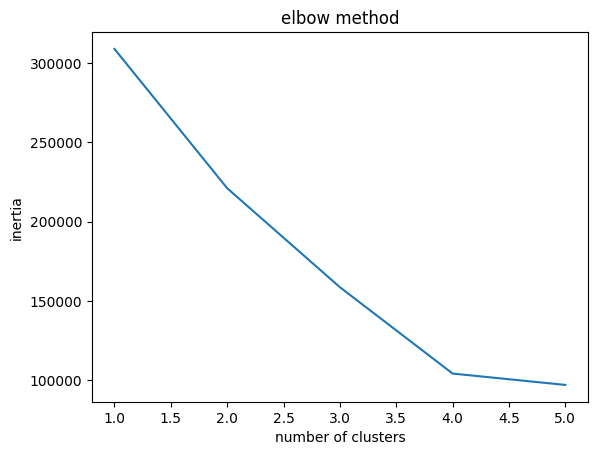

In [19]:
inertia = []
for k in range(1,6):
  model = KMeans(n_clusters = k,random_state=42)
  model.fit(X)
  inertia.append(model.inertia_)
plt.plot(range(1,6), inertia)
plt.xlabel("number of clusters")
plt.ylabel("inertia")
plt.title("elbow method")
plt.show()



In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [21]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

In [22]:
df['Cluster'] = y_kmeans

In [23]:
df.to_csv("Mall_Customers.csv", index=False)

In [24]:
df['Cluster'].value_counts()

,count
Cluster,
0,65
2,57
1,40
3,38


In [25]:
df.groupby('Cluster')[X.columns].mean()

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,53.984615,47.707692,39.969231
1,32.875000,86.100000,81.525000
2,25.438596,40.000000,60.298246
3,39.368421,86.500000,19.578947


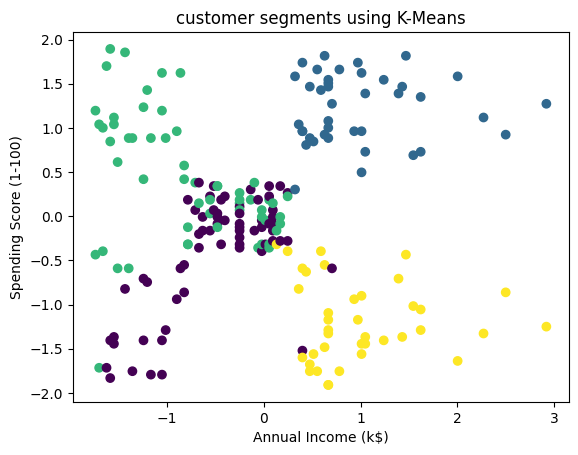

In [26]:
plt.scatter(
    X_scaled[:,1],
    X_scaled[:,2],
    c=y_kmeans
    )
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('customer segments using K-Means')
plt.show()


Conclusion:
K-Means clustering was successfully applied to the Mall Customers dataset to segment customers based on Age, Annual Income, and Spending Score. The Elbow Method was used to determine the suitable number of clusters, resulting in 4 customer segments. The clusters were visualized using a scatter plot, and the resulting cluster labels were added to the dataset. This segmentation helps identify groups of customers with similar characteristics and spending behavior.